# Virtue of Complexity or Volatility-Timed Momentum?
## Baseline checkpoint

Walk-forward, out-of-sample forecasts of next month's S&P 500 excess return from the Goyal–Welch predictors (`PredictorData2025.xlsx`, from [Amit Goyal's website](https://sites.google.com/view/agoyal145)).

**No look-ahead:** every standardization and every penalty choice uses only data available before the forecast date. Penalties are chosen on a validation period (targets 1950–1979); the test period (targets 1980–2025) is scored once, at the end.

Put `PredictorData2025.xlsx` in the same folder as this notebook, then run all cells (about 1 minute).

In [1]:
DATA_PATH = "PredictorData2025.xlsx"   # change if the file is elsewhere

In [2]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

SEED = 2026
T = 12                                   # training window (months), as in Kelly et al.
LAMBDAS = [1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0, 1000.0]
P_GRID = [2, 6, 12, 60, 120, 600, 1200, 6000, 12000]
N_DRAWS = 20                             # random-weight draws per P
GAMMA = 2.0                              # random Fourier feature scale
MIN_HIST = 36                            # months of history before standardizing
OLS_MIN = 240                            # expanding-window OLS needs 20 years
VAL = (195001, 197912)                   # target months used for tuning
TEST = (198001, 202512)                  # target months scored once
BLOCK, B = 12, 2000                      # block bootstrap: 12-month blocks

## 1. Data
15 predictors known at the end of month *t*; the target is the excess return of month *t*+1. Inflation is lagged one extra month because CPI is published with a delay. Predictors are z-scored with expanding means and standard deviations up to *t* only.

In [3]:
def load(path):
    m = pd.read_excel(path, sheet_name="Monthly").replace("NaN", np.nan)
    m = m.apply(pd.to_numeric, errors="coerce")
    m = m[m.yyyymm >= 192601].reset_index(drop=True)
    exret = m["CRSP_SPvw"] - m["Rfree"]
    lp, ld, le = np.log(m["Index"]), np.log(m["D12"]), np.log(m["E12"])
    X = pd.DataFrame({
        "dp": ld - lp,
        "dy": ld - lp.shift(1),
        "ep": le - lp,
        "de": ld - le,
        "svar": m["svar"],
        "bm": m["b/m"],
        "ntis": m["ntis"],
        "tbl": m["tbl"],
        "lty": m["lty"],
        "ltr": m["ltr"],
        "tms": m["lty"] - m["tbl"],
        "dfy": m["BAA"] - m["AAA"],
        "dfr": m["corpr"] - m["ltr"],
        "infl": m["infl"].shift(1),      # CPI is published with a lag
        "lagret": exret,                 # this month's excess return
    })
    y = exret.shift(-1)                  # target: next month's excess return
    keep = X.notna().all(axis=1) & y.notna()
    first, last = keep.idxmax(), keep[::-1].idxmax()
    X, y, ym = X.loc[first:last], y.loc[first:last], m["yyyymm"].loc[first:last]
    assert X.notna().all().all() and y.notna().all(), "unexpected gaps"
    target_ym = m["yyyymm"].shift(-1).loc[first:last].astype(int)
    return (X.reset_index(drop=True), y.reset_index(drop=True).values,
            ym.reset_index(drop=True).values.astype(int),
            target_ym.reset_index(drop=True).values, exret)


def standardize_past_only(X):
    """z-score month t using the mean and std of months <= t only."""
    mu = X.expanding(MIN_HIST).mean()
    sd = X.expanding(MIN_HIST).std()
    return ((X - mu) / sd).values        # NaN for the first MIN_HIST-1 months


X, y, ym, tym, exret = load(DATA_PATH)
Z = standardize_past_only(X)
valid = ~np.isnan(Z).any(axis=1)
n = len(y)
val = (tym >= VAL[0]) & (tym <= VAL[1])
test = (tym >= TEST[0]) & (tym <= TEST[1])
print(f"N = {n} months, targets {tym[0]} to {tym[-1]}, {X.shape[1]} inputs")
print(f"Validation months: {val.sum()},  test months: {test.sum()}")
X.describe().T[['mean', 'std', 'min', 'max']].round(4)

N = 1188 months, targets 192701 to 202512, 15 inputs
Validation months: 360,  test months: 552


,mean,std,min,max
dp,-3.4349,0.4926,-4.5236,-1.8732
dy,-3.4296,0.4901,-4.5309,-1.9129
ep,-2.7764,0.4231,-4.8365,-1.7750
de,-0.6585,0.3288,-1.2442,1.3795
svar,0.0029,0.0059,0.0001,0.0732
bm,0.5414,0.2711,0.1205,2.0285
ntis,0.0151,0.0258,-0.0560,0.1770
tbl,0.0334,0.0303,0.0001,0.1630
lty,0.0494,0.0277,0.0062,0.1482
ltr,0.0046,0.0245,-0.1124,0.1523


## 2. Models
- **Historical mean:** average of all past excess returns (the benchmark).
- **OLS (expanding window):** kitchen-sink regression; reproduces the Goyal–Welch finding.
- **Ridge (T = 12):** the baseline, on the 15 predictors, rolling 12-month window, no intercept.
- **Random-feature ridge (T = 12):** ridge on *P* random Fourier features sin/cos(γ ωᵀz), ω ~ N(0, I), γ = 2.

With *P* far above *T*, ridge is solved in its *T* × *T* kernel form, so *P* = 12,000 stays cheap.

In [4]:
def hist_mean(y, exret_full, ym):
    """Mean of all excess returns observed up to and including month t."""
    full = exret_full.values
    out = np.empty(len(y))
    # index of month t in the full series: data start 192601 at position 0
    first_pos = (ym[0] // 100 - 1926) * 12 + (ym[0] % 100 - 1)
    for i in range(len(y)):
        out[i] = np.nanmean(full[: first_pos + i + 1])
    return out


def ols_expanding(Z, y):
    """Kitchen-sink OLS with intercept, expanding window (Goyal-Welch check)."""
    n = len(y)
    out = np.full(n, np.nan)
    for t in range(n):
        tr = np.arange(0, t)             # pairs (z_s, y_s) with s < t are known
        tr = tr[~np.isnan(Z[tr]).any(axis=1)]
        if len(tr) < OLS_MIN or np.isnan(Z[t]).any():
            continue
        A = np.column_stack([np.ones(len(tr)), Z[tr]])
        b = np.linalg.lstsq(A, y[tr], rcond=None)[0]
        out[t] = b[0] + Z[t] @ b[1:]
    return out


def kernel_ridge_rolling(G, y, lam, valid):
    """Rolling-window ridge (no intercept) in its T x T kernel form.

    G is the Gram matrix of the (scaled) features: G[s, t] = f_s . f_t.
    Forecast at t uses training pairs s = t-T .. t-1:
        yhat_t = G[t, S] (G[S, S] + lam*T*I)^{-1} y[S]
    which equals ridge with objective (1/T)||y - Fb||^2 + lam ||b||^2.
    """
    n = len(y)
    out = np.full(n, np.nan)
    I = np.eye(T)
    for t in range(T, n):
        S = np.arange(t - T, t)
        if not (valid[S].all() and valid[t]):
            continue
        K = G[np.ix_(S, S)]
        k = G[t, S]
        out[t] = k @ np.linalg.solve(K + lam * T * I, y[S])
    return out


def rff_gram(Z, P, rng):
    """Gram matrix of P random Fourier features (P/2 sin, P/2 cos), scaled 1/P."""
    Zf = np.nan_to_num(Z)
    W = rng.standard_normal((Zf.shape[1], max(P // 2, 1)))
    H = GAMMA * Zf @ W
    F = np.hstack([np.sin(H), np.cos(H)])[:, :P]
    return (F @ F.T) / P

## 3. Metrics and block bootstrap
R²_OOS is measured against the historical mean. The timing strategy's position equals the forecast. Forecasts are serially correlated, so intervals come from a circular block bootstrap with 12-month blocks.

In [5]:
def r2_oos(y, f, bench):
    return 1.0 - np.sum((y - f) ** 2) / np.sum((y - bench) ** 2)


def sharpe(y, f):
    r = f * y                            # position = forecast
    return np.sqrt(12) * r.mean() / r.std(ddof=1)


def block_indices(n, rng):
    starts = rng.integers(0, n, size=int(np.ceil(n / BLOCK)))
    idx = (starts[:, None] + np.arange(BLOCK)[None, :]) % n   # circular blocks
    return idx.ravel()[:n]


def bootstrap(stat_fn, n, seed):
    rng = np.random.default_rng(seed)
    vals = np.array([stat_fn(block_indices(n, rng)) for _ in range(B)])
    return np.percentile(vals, [2.5, 97.5])

## 4. Baselines, with the ridge penalty tuned on the validation period only

In [6]:
hm = hist_mean(y, exret, ym)
fc = {"Historical mean": hm, "OLS (expanding)": ols_expanding(Z, y)}

G_lin = np.nan_to_num(Z) @ np.nan_to_num(Z).T
ridge_val, ridge_fc = {}, {}
for lam in LAMBDAS:
    f = kernel_ridge_rolling(G_lin, y, lam, valid)
    ridge_fc[lam] = f
    ridge_val[lam] = r2_oos(y[val], f[val], hm[val])
lam_ridge = max(ridge_val, key=ridge_val.get)
fc["Ridge (T=12)"] = ridge_fc[lam_ridge]

print("Validation R2_OOS by lambda:")
for lam, v in ridge_val.items():
    print(f"  lambda = {lam:<7g} {100 * v:7.2f}%")
print("Chosen lambda:", lam_ridge)

Validation R2_OOS by lambda:
  lambda = 0.001   -234.87%
  lambda = 0.01    -127.51%
  lambda = 0.1      -67.48%
  lambda = 1        -15.81%
  lambda = 10        -2.86%
  lambda = 100       -1.79%
  lambda = 1000      -2.10%
Chosen lambda: 100.0


## 5. Random-feature ridge: 20 weight draws per *P*
The penalty is chosen per *P* by the validation score averaged over draws. All draws are kept and reported; none is selected.

In [7]:
rng = np.random.default_rng(SEED)
rff = {}
for P in P_GRID:
    draws = {lam: [] for lam in LAMBDAS}
    for d in range(N_DRAWS):
        G = rff_gram(Z, P, rng)
        for lam in LAMBDAS:
            draws[lam].append(kernel_ridge_rolling(G, y, lam, valid))
    val_score = {lam: np.mean([r2_oos(y[val], f[val], hm[val]) for f in draws[lam]])
                 for lam in LAMBDAS}
    lam_best = max(val_score, key=val_score.get)
    rff[P] = {"lam": lam_best, "fc": np.array(draws[lam_best])}
    print(f"P = {P:>6}: lambda = {lam_best}")

P =      2: lambda = 10.0
P =      6: lambda = 1.0
P =     12: lambda = 1.0
P =     60: lambda = 1.0
P =    120: lambda = 1.0
P =    600: lambda = 0.1
P =   1200: lambda = 0.1
P =   6000: lambda = 0.1
P =  12000: lambda = 0.1


## 6. Test period 1980–2025, scored once

In [8]:
yt, hmt = y[test], hm[test]
nt = test.sum()
print(f"Buy-and-hold Sharpe ratio: {np.sqrt(12) * yt.mean() / yt.std(ddof=1):.2f}")

rows = []
for i, (name, f) in enumerate(fc.items()):
    ft = f[test]
    assert not np.isnan(ft).any(), name
    r2_ci = bootstrap(lambda ix: r2_oos(yt[ix], ft[ix], hmt[ix]), nt, SEED + i)
    sr_ci = bootstrap(lambda ix: sharpe(yt[ix], ft[ix]), nt, SEED + 100 + i)
    rows.append({"Model": name, "R2_OOS (%)": 100 * r2_oos(yt, ft, hmt),
                 "R2 95% CI": f"[{100 * r2_ci[0]:.2f}, {100 * r2_ci[1]:.2f}]",
                 "Sharpe": sharpe(yt, ft),
                 "Sharpe 95% CI": f"[{sr_ci[0]:.2f}, {sr_ci[1]:.2f}]"})
pd.DataFrame(rows).set_index("Model").round(3)

Buy-and-hold Sharpe ratio: 0.59


,R2_OOS (%),R2 95% CI,Sharpe,Sharpe 95% CI
Model,,,,
Historical mean,0.000,"[0.00, 0.00]",0.578,"[0.27, 0.90]"
OLS (expanding),-10.608,"[-17.89, -4.06]",0.070,"[-0.17, 0.47]"
Ridge (T=12),-2.509,"[-5.48, 0.26]",0.130,"[-0.07, 0.41]"


In [9]:
rows = []
for j, P in enumerate(P_GRID):
    F = rff[P]["fc"][:, test]                       # draws x months
    r2_d = np.array([r2_oos(yt, f, hmt) for f in F])
    sr_d = np.array([sharpe(yt, f) for f in F])
    row = {"P": P, "lambda": rff[P]["lam"],
           "R2_OOS mean (%)": 100 * r2_d.mean(), "R2 draw SD (%)": 100 * r2_d.std(ddof=1),
           "Sharpe mean": sr_d.mean(), "Sharpe draw SD": sr_d.std(ddof=1)}
    if P in (12, 1200, 12000):   # bootstrap: months resampled jointly across draws
        r2_ci = bootstrap(lambda ix: np.mean([r2_oos(yt[ix], f[ix], hmt[ix]) for f in F]),
                          nt, SEED + 200 + j)
        sr_ci = bootstrap(lambda ix: np.mean([sharpe(yt[ix], f[ix]) for f in F]),
                          nt, SEED + 300 + j)
        row["R2 95% CI"] = f"[{100 * r2_ci[0]:.2f}, {100 * r2_ci[1]:.2f}]"
        row["Sharpe 95% CI"] = f"[{sr_ci[0]:.2f}, {sr_ci[1]:.2f}]"
        row["_ci"] = (r2_ci, sr_ci)
    rows.append(row)
rff_table = pd.DataFrame(rows).set_index("P")
rff_table.drop(columns="_ci").round(3).fillna("")

,lambda,R2_OOS mean (%),R2 draw SD (%),Sharpe mean,Sharpe draw SD,R2 95% CI,Sharpe 95% CI
P,,,,,,,
2,10.0,-2.765,0.092,-0.009,0.150,,
6,1.0,-2.888,0.422,0.047,0.129,,
12,1.0,-2.838,0.290,0.029,0.117,"[-5.84, -0.13]","[-0.05, 0.11]"
60,1.0,-2.760,0.157,0.028,0.135,,
120,1.0,-2.729,0.141,0.054,0.169,,
600,0.1,-2.665,0.403,0.126,0.126,,
1200,0.1,-2.550,0.157,0.170,0.062,"[-5.53, -0.00]","[-0.07, 0.43]"
6000,0.1,-2.469,0.126,0.227,0.064,,
12000,0.1,-2.491,0.068,0.222,0.037,"[-5.41, -0.10]","[-0.14, 0.54]"


## 7. Figure

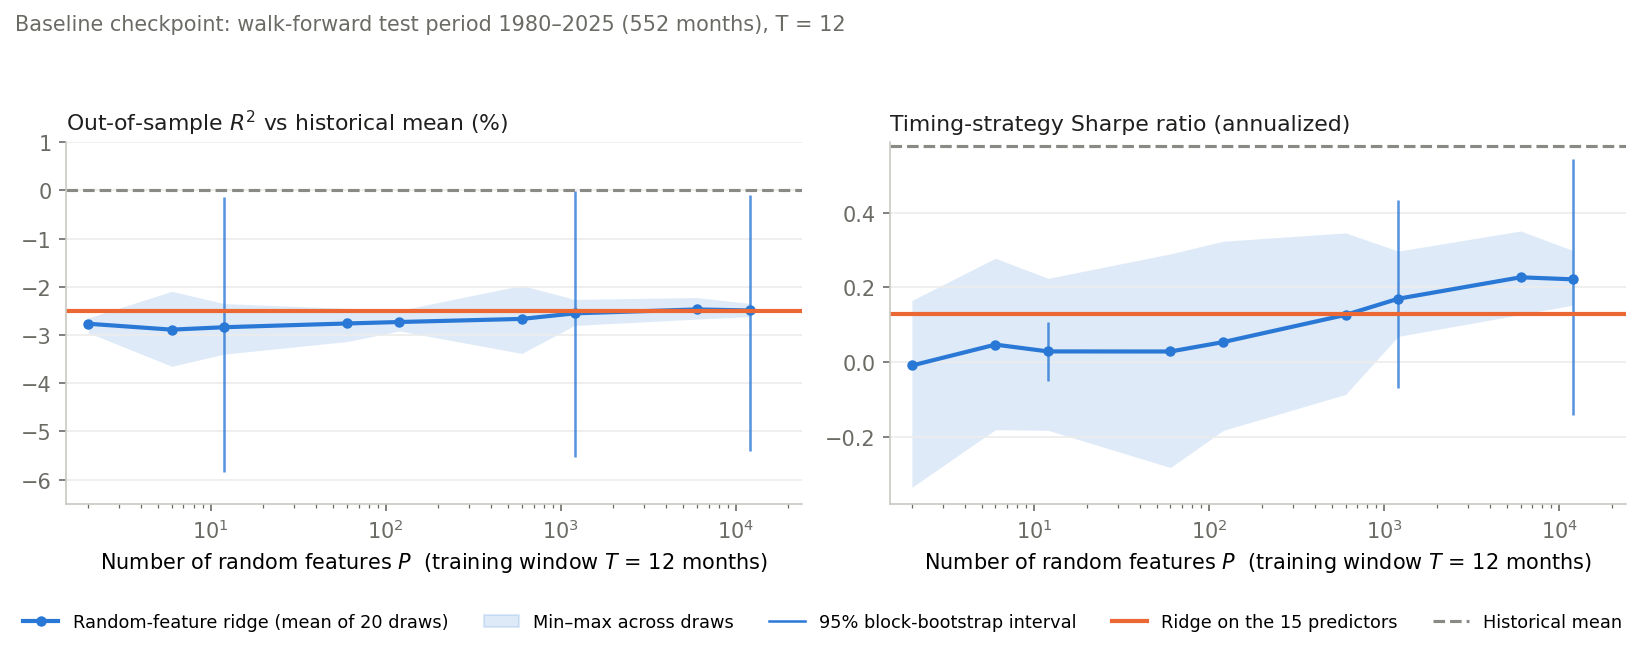

In [10]:
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8a85"
INK, MUTED = "#1f1f1e", "#6b6b66"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": "#c9c9c4",
                     "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False})
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

def per_draw(P, metric):
    F = rff[P]["fc"][:, test]
    if metric == "r2":
        return np.array([r2_oos(yt, f, hmt) for f in F]) * 100
    return np.array([sharpe(yt, f) for f in F])

ridge_r2 = 100 * r2_oos(yt, fc["Ridge (T=12)"][test], hmt)
ridge_sr = sharpe(yt, fc["Ridge (T=12)"][test])
hm_sr = sharpe(yt, hmt)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), dpi=150)
panels = [("r2", "Out-of-sample $R^2$ vs historical mean (%)", ridge_r2, 0.0, 0, 100),
          ("sr", "Timing-strategy Sharpe ratio (annualized)", ridge_sr, hm_sr, 1, 1)]
for ax, (key, title, ridge_v, hm_v, ci_i, scale) in zip(axes, panels):
    D = np.array([per_draw(P, key) for P in P_GRID])
    ax.fill_between(P_GRID, D.min(1), D.max(1), color=BLUE, alpha=0.15, linewidth=0)
    ax.plot(P_GRID, D.mean(1), color=BLUE, lw=2, marker="o", ms=4)
    for P in (12, 1200, 12000):
        ci = np.array(rff_table.loc[P, "_ci"][ci_i]) * scale
        ax.vlines(P, ci[0], ci[1], color=BLUE, lw=1.2, alpha=0.8)
    ax.axhline(hm_v, color=GRAY, lw=1.5, ls="--")
    ax.axhline(ridge_v, color=ORANGE, lw=2)
    ax.set_xscale("log")
    ax.set_xlim(1.5, P_GRID[-1] * 2)
    ax.set_xlabel("Number of random features $P$  (training window $T$ = 12 months)")
    ax.set_title(title, fontsize=10.5, color=INK, loc="left")
    ax.grid(axis="y", color="#ececea", lw=0.8)
axes[0].set_ylim(-6.5, 1)
handles = [Line2D([], [], color=BLUE, lw=2, marker="o", ms=4, label="Random-feature ridge (mean of 20 draws)"),
           Patch(color=BLUE, alpha=0.15, label="Min–max across draws"),
           Line2D([], [], color=BLUE, lw=1.2, label="95% block-bootstrap interval"),
           Line2D([], [], color=ORANGE, lw=2, label="Ridge on the 15 predictors"),
           Line2D([], [], color=GRAY, lw=1.5, ls="--", label="Historical mean")]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, fontsize=8.5)
fig.suptitle("Baseline checkpoint: walk-forward test period 1980–2025 (552 months), T = 12",
             fontsize=10, color=MUTED, x=0.01, ha="left", y=0.995)
fig.tight_layout(rect=(0, 0.07, 1, 0.95))
fig.savefig("baseline.png", facecolor="white")
plt.show()